In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


# 05 · Context quality and robustness

## tl;dr
Controlled label noise changes context labels only. Duplicate examples replace 20% of a fixed 128-row context; a DACH-only context tests a synthetic regional distribution shift. All use the same final holdout.

## Methods
Noise levels are 0%, 5%, 10%, and 20%; flip positions are deterministic by seed. Symmetric flips change the effective fraud class prior because fraud is rare, so the test combines mislabeling and prior shift. Duplicate copies receive unique request IDs while retaining feature/label content. The regional intervention restricts context to DACH; it is a synthetic shift, not a claim about production regions.

In [2]:
noise=pd.read_csv(ROOT/'data/context_benchmark/noise_results.csv')
quality=pd.read_csv(ROOT/'data/context_benchmark/quality_results.csv')
display(noise.groupby(['target','noise_percent'])[['f1','recall','false_positives']].agg(['mean','std']).round(3))
display(quality.groupby(['target','strategy'])[['f1','recall','false_positives']].agg(['mean','std']).round(3))

f1        recall        false_positives        
                          mean    std   mean    std            mean     std
target    noise_percent                                                    
is_fraud  0              0.000  0.000  0.000  0.000             0.0   0.000
          5              0.000  0.000  0.000  0.000             0.0   0.000
          10             0.036  0.081  0.025  0.056             0.4   0.894
          20             0.000  0.000  0.000  0.000             0.0   0.000
paid_late 0              0.544  0.031  0.557  0.093            24.6   6.693
          5              0.567  0.041  0.635  0.123            30.2   9.094
          10             0.386  0.242  0.388  0.287            17.4  15.994
          20             0.301  0.265  0.396  0.455            25.6  33.545

f1        recall       false_positives       
                         mean    std   mean   std            mean    std
target    strategy                                                      
is_fraud  duplicate     0.000  0.000  0.000  0.00             0.0  0.000
          region_shift  0.000  0.000  0.000  0.00             0.0  0.000
paid_late duplicate     0.540  0.043  0.529  0.08            21.8  7.727
          region_shift  0.534  0.040  0.561  0.08            27.2  6.261

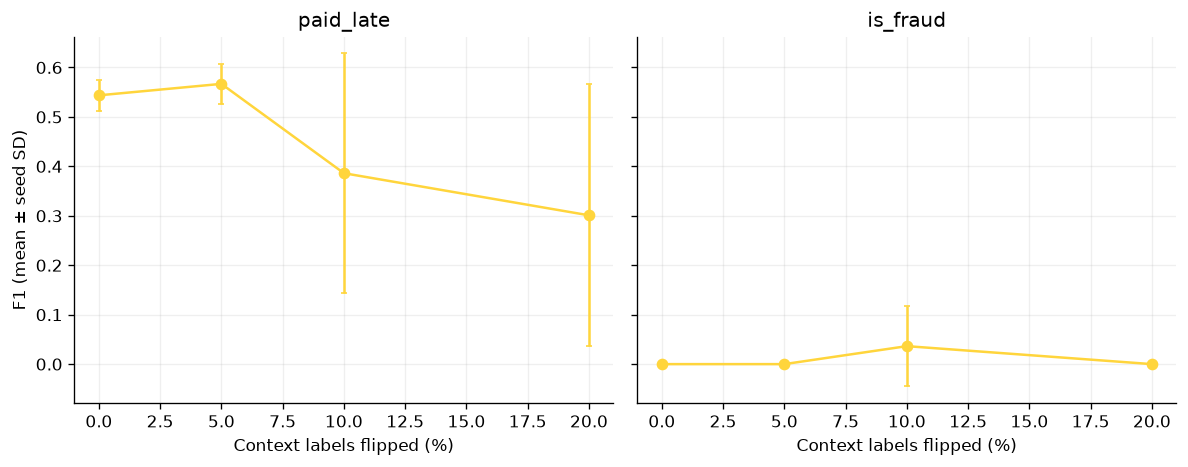

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,target in zip(axes,['paid_late','is_fraud']):
    sub=noise[noise.target==target].groupby('noise_percent').f1.agg(['mean','std'])
    ax.errorbar(sub.index,sub['mean'],yerr=sub['std'].fillna(0),marker='o',capsize=2,color='#FFD53C'); ax.set_title(target); ax.set_xlabel('Context labels flipped (%)'); ax.grid(alpha=.2)
axes[0].set_ylabel('F1 (mean ± seed SD)'); plt.tight_layout(); plt.show()

## Takeaways
These interventions change different aspects of context and should be interpreted separately. In particular, regional restriction changes the context population; it does not test semantic understanding.